# 02 · 销售与渠道分析

基于清洗后的 `data/processed/` 宽表，围绕一个核心问题：

> **一个小厂，如何用最低的成本（一个展厅 + 一条抖音）把单子做起来、把钱赚稳？**

分析路径：整体概览 → 增长趋势 → 季节性 → 品类结构 → 渠道效能 → 客户价值 → 交付与售后 → 结论建议

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

PROJECT = Path(".").resolve()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
FIG = PROJECT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

orders    = pd.read_csv(PROJECT / "data/processed/orders_clean.csv", parse_dates=["order_date"])
items     = pd.read_csv(PROJECT / "data/processed/item_flat.csv")
rfm       = pd.read_csv(PROJECT / "data/processed/customer_rfm.csv")
customers = pd.read_csv(PROJECT / "data/raw/customers.csv")
after     = pd.read_csv(PROJECT / "data/raw/after_sales.csv", parse_dates=["report_date"])

valid = orders[orders["is_valid"] == 1].copy()
print("数据就绪：共", orders.shape[0], "张订单，其中有效", valid.shape[0], "张")

数据就绪：共 2401 张订单，其中有效 2232 张


### 1. 整体概览（2023-01 ~ 2026-07）

In [2]:
gmv = valid["final_amount"].sum()
print(f"有效订单 {len(valid):,} 单，成交额 ¥{gmv:,.0f}（约 {gmv/1e8:.2f} 亿）")
print(f"客单价 ¥{valid['final_amount'].mean():,.0f}，单笔最高 ¥{valid['final_amount'].max():,.0f}")

yearly = valid.groupby(valid["order_date"].dt.year)["final_amount"].agg(["sum", "count"])
yearly["客单价"] = yearly["sum"] / yearly["count"]
yearly.index = [f"{y}年" for y in yearly.index]
print("\n按年度（2026 为前 7 个月）：")
print(yearly.round(0).to_string())

有效订单 2,232 单，成交额 ¥59,814,329（约 0.60 亿）
客单价 ¥26,799，单笔最高 ¥261,657

按年度（2026 为前 7 个月）：
              sum  count      客单价
2023年   9249925.0    332  27861.0
2024年  16134973.0    587  27487.0
2025年  21462395.0    810  26497.0
2026年  12967037.0    503  25779.0


### 2. 增长趋势：从建厂到爬坡

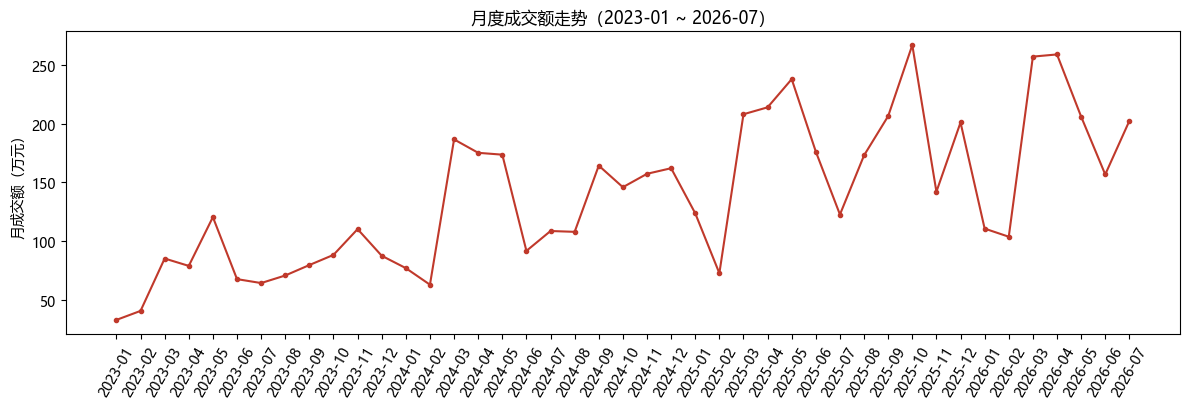

In [3]:
monthly = valid.groupby(valid["order_date"].dt.to_period("M"))["final_amount"].agg(["sum", "count"])
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(monthly.index.astype(str), monthly["sum"] / 1e4, marker="o", ms=3, lw=1.5, color="#c0392b")
ax.set_ylabel("月成交额（万元）")
ax.set_title("月度成交额走势（2023-01 ~ 2026-07）")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG / "02_月度GMV趋势.png", dpi=130); plt.show()

### 3. 季节性：门业有「金三银四、金九银十」

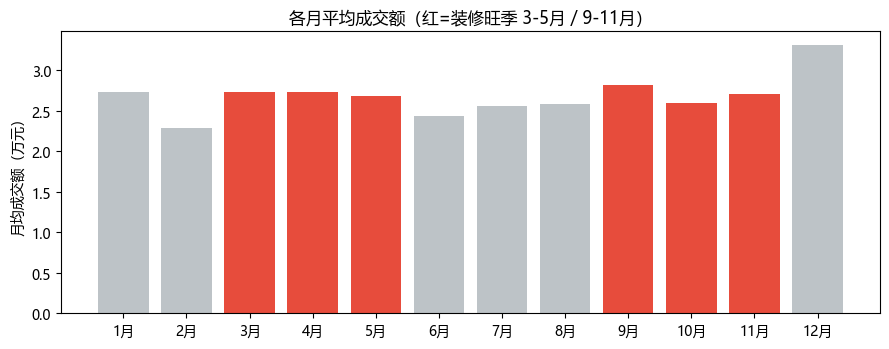

In [4]:
season = valid.groupby("order_month")["final_amount"].mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = ["#e74c3c" if m in (3, 4, 5, 9, 10, 11) else "#bdc3c7" for m in season.index]
ax.bar(season.index, season / 1e4, color=colors)
ax.set_xticks(range(1, 13)); ax.set_xticklabels([f"{m}月" for m in range(1, 13)])
ax.set_ylabel("月均成交额（万元）")
ax.set_title("各月平均成交额（红=装修旺季 3-5月 / 9-11月）")
plt.tight_layout(); plt.savefig(FIG / "02_季节性.png", dpi=130); plt.show()

### 4. 品类结构：谁在赚钱（帕累托 80/20）

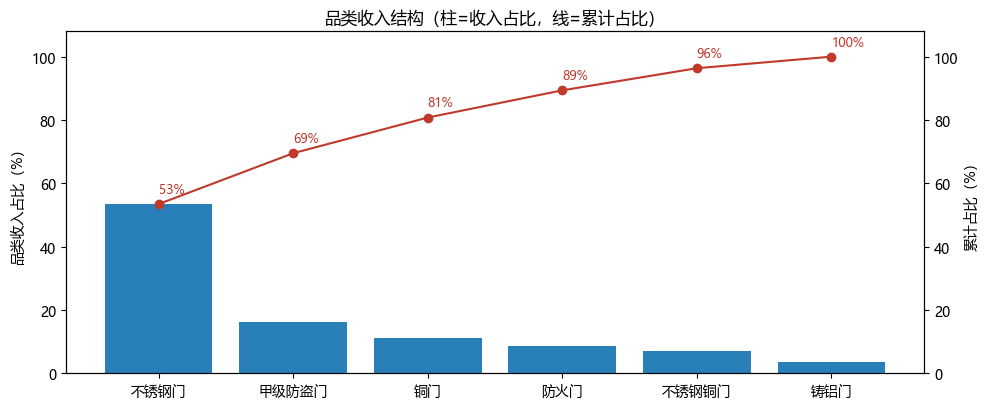

品类平均单价（元/樘）与收入占比：
               均价  收入占比%
category                
不锈钢门      14177.0   53.4
甲级防盗门      6145.0   16.1
铜门        11907.0   11.3
防火门        3111.0    8.6
不锈钢铜门     10331.0    7.0
铸铝门        7798.0    3.7


In [5]:
cat = items.groupby("category")["line_amount"].sum().sort_values(ascending=False)
cat_share = cat / cat.sum() * 100
cum = cat_share.cumsum()

fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.bar(cat.index, cat_share, color="#2980b9")
ax1.set_ylabel("品类收入占比（%）"); ax1.set_ylim(0, 108)
ax2 = ax1.twinx()
ax2.plot(cum.index, cum, color="#c0392b", marker="o")
ax2.set_ylabel("累计占比（%）"); ax2.set_ylim(0, 108)
for i, (c, p) in enumerate(cum.items()):
    ax2.annotate(f"{p:.0f}%", (i, p), textcoords="offset points", xytext=(0, 8),
                 fontsize=9, color="#c0392b")
ax1.set_title("品类收入结构（柱=收入占比，线=累计占比）")
plt.tight_layout(); plt.savefig(FIG / "02_品类结构_帕累托.png", dpi=130); plt.show()

aov_cat = items.groupby("category")["unit_price"].mean().round(0)
print("品类平均单价（元/樘）与收入占比：")
print(pd.concat([aov_cat.rename("均价"), cat_share.rename("收入占比%")], axis=1)
      .round(1).sort_values("收入占比%", ascending=False).to_string())

### 5. 渠道效能：抖音值不值？转介靠不靠得住？

In [6]:
ch = valid.groupby("channel").agg(orders=("order_id", "count"), gmv=("final_amount", "sum"),
                                        aov=("final_amount", "mean"))
ch["gmv_share"] = ch["gmv"] / ch["gmv"].sum() * 100
print(ch.sort_values("gmv", ascending=False).round(0).to_string())

# 渠道「注册→成交」转化率：以全部注册客户（含线索）为分母
conv = customers.groupby("channel")["is_lead"].apply(lambda s: (s == 0).mean() * 100)
print("\n渠道「注册→成交」转化率（%）：")
print(conv.sort_values(ascending=False).round(1).to_string())

         orders         gmv      aov  gmv_share
channel                                        
装修公司合作      488  17656997.0  36182.0       30.0
老客户转介       569  14993011.0  26350.0       25.0
抖音短视频       492  10930727.0  22217.0       18.0
展会营销        223   6520454.0  29240.0       11.0
门店到访        310   6412577.0  20686.0       11.0
线上渠道        150   3300563.0  22004.0        6.0

渠道「注册→成交」转化率（%）：
channel
线上渠道      87.3
装修公司合作    86.1
抖音短视频     81.4
门店到访      81.3
老客户转介     81.3
展会营销      77.5


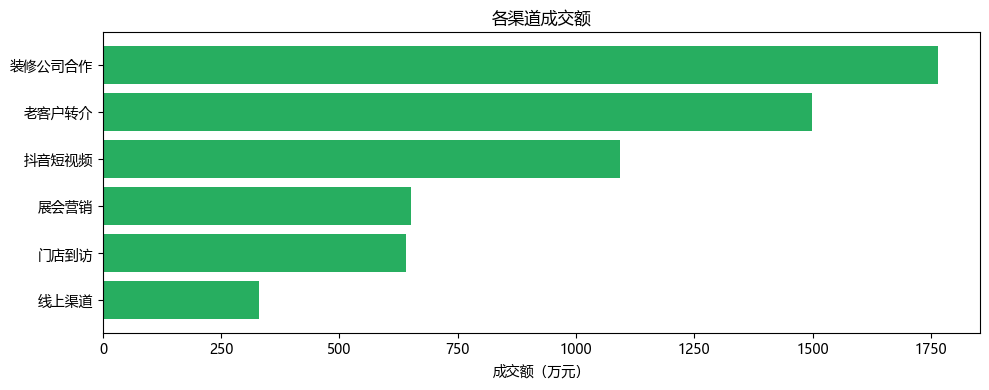

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ch_sorted = ch.sort_values("gmv")
ax.barh(ch_sorted.index, ch_sorted["gmv"] / 1e4, color="#27ae60")
ax.set_xlabel("成交额（万元）")
ax.set_title("各渠道成交额")
plt.tight_layout(); plt.savefig(FIG / "02_渠道GMV.png", dpi=130); plt.show()

### 6. 客户价值：高价值客户是谁

In [8]:
seg = rfm.groupby("segment").agg(客户数=("customer_id", "count"), 累计消费=("monetary", "sum"),
                                       人均消费=("monetary", "mean"))
seg["收入占比%"] = seg["累计消费"] / seg["累计消费"].sum() * 100
print(seg.round(0).to_string())

hv = rfm[rfm["segment"] == "高价值客户"]
print("\n高价值客户画像（n =", len(hv), "）：")
print("  人均消费 ¥{:,.0f}，平均下单 {:.1f} 次".format(hv["monetary"].mean(), hv["frequency"].mean()))
print("  主要类型：", hv["customer_type"].value_counts(normalize=True).round(2).head(3).to_dict())
print("  主要来源：", hv["channel"].value_counts(normalize=True).round(2).head(3).to_dict())
print("  主要城市：", hv["city"].value_counts().head(5).to_dict())

         客户数        累计消费      人均消费  收入占比%
segment                                  
成长潜力     161   9475966.0   58857.0   16.0
新客户      215   3870911.0   18004.0    6.0
沉睡客户     391   8855927.0   22649.0   15.0
需挽留      203  13153744.0   64797.0   22.0
高价值客户    213  24457780.0  114825.0   41.0

高价值客户画像（n = 213 ）：
  人均消费 ¥114,825，平均下单 3.7 次
  主要类型： {'装修公司': 0.7, '个人家装': 0.25, '工程客户': 0.05}
  主要来源： {'装修公司合作': 0.46, '老客户转介': 0.24, '展会营销': 0.14}
  主要城市： {'嘉兴': 30, '海宁': 26, '桐乡': 21, '杭州': 18, '苏州': 11}


### 7. 交付与售后：运营短板在哪

In [9]:
done = valid[valid["order_status"] == "已完成"]
print("整体准时率 {:.1f}%".format(done["is_on_time"].mean() * 100))
print("实际交付周期中位数 {:.0f} 天".format(done["actual_lead_days"].median()))
lead_cat = done.groupby("dominant_category")["actual_lead_days"].median().sort_values()
print("各品类交付周期（天，中位）：", lead_cat.round(0).to_dict())

print("\n售后问题分布：")
print(after["type"].value_counts().to_string())

as_cat = after[after["type"] != "退款"].groupby("product_id").size()
dn_cat = valid.groupby("dominant_category").size()
rate = (as_cat / dn_cat.reindex(as_cat.index) * 100).sort_values(ascending=False)
print("\n各品类售后率（%）：", rate.round(1).to_dict())

整体准时率 79.7%
实际交付周期中位数 28 天
各品类交付周期（天，中位）： {'甲级防盗门': 22.0, '防火门': 22.0, '不锈钢门': 30.0, '不锈钢铜门': 38.0, '铸铝门': 45.0, '铜门': 58.0}

售后问题分布：
type
退款      58
安装问题    30
色差      23
五金损坏    20
尺寸误差    17
门体变形    17
售后咨询    12
物流破损    12

各品类售后率（%）： {'铸铝门': 12.6, '铜门': 7.8, '不锈钢铜门': 6.8, '不锈钢门': 6.2, '甲级防盗门': 4.5, '防火门': 2.5}


### 8. 结论与建议

**① 增长引擎 = 抖音获客 + 老客户转介，2023 年建厂后持续爬坡**
- 成交额从 2023 年约 ¥925 万 → 2024 年 ¥1,613 万 → 2025 年 ¥2,146 万，3 年近 2.3 倍。
- 抖音是订单第二大来源（492 单）、几乎零店面成本，是放量的主引擎 → 短视频内容标准化 + 持续投流放大。
- 老客户转介单量最大（569 单）且成本最低 → 建立转介绍激励，维护口碑。

**② 收入高度依赖不锈钢门，品类结构偏单一**
- 不锈钢门单品类贡献 53% 收入，前 3 个品类（不锈钢门/甲级防盗门/铜门）合计约 8 成（80/20 明显）。
- 铜门均价高（¥1.2 万/樘）、利润厚但占比仅 11% → 主推「铜门+不锈钢」组合方案：不锈钢跑量、铜门做利润。

**③ 装企合作是高客单渠道，值得重点经营**
- 装企合作客单价 ¥3.6 万（全渠道最高）、贡献 30% 收入，也是高价值客户（占 70%）的主要来源。
- 建议服务好 2-3 家重点装企，形成稳定复购。

**④ 交付准时率约 8 成，是运营短板**
- 准时率 79.7%，交付周期中位 28 天；铜门周期最长（58 天），延期风险最高。
- 建议下单时给足交付预期，关键节点（确认图纸→排产→发货）对客户可见，降低投诉与退单。

**⑤ 高价值客户是利润基本盘**
- 高价值客户 213 名（占 18%），贡献 41% 收入，人均消费 ¥11.5 万、复购 3.7 次，以装企和本地客户（嘉兴/海宁/桐乡）为主。
- 建议专属权益 + 复购引导；沉睡客户占比高是门业低频的天然属性，与其硬唤醒，不如引导其转介绍。